In [1]:
!pip install opencv-python scipy matplotlib -i http://pypi.tuna.tsinghua.edu.cn/simple --trusted-host pypi.tuna.tsinghua.edu.cn

Looking in indexes: http://pypi.tuna.tsinghua.edu.cn/simple


Loading data...
Extracting contours and curvature...
Generating Acta-style Plot...


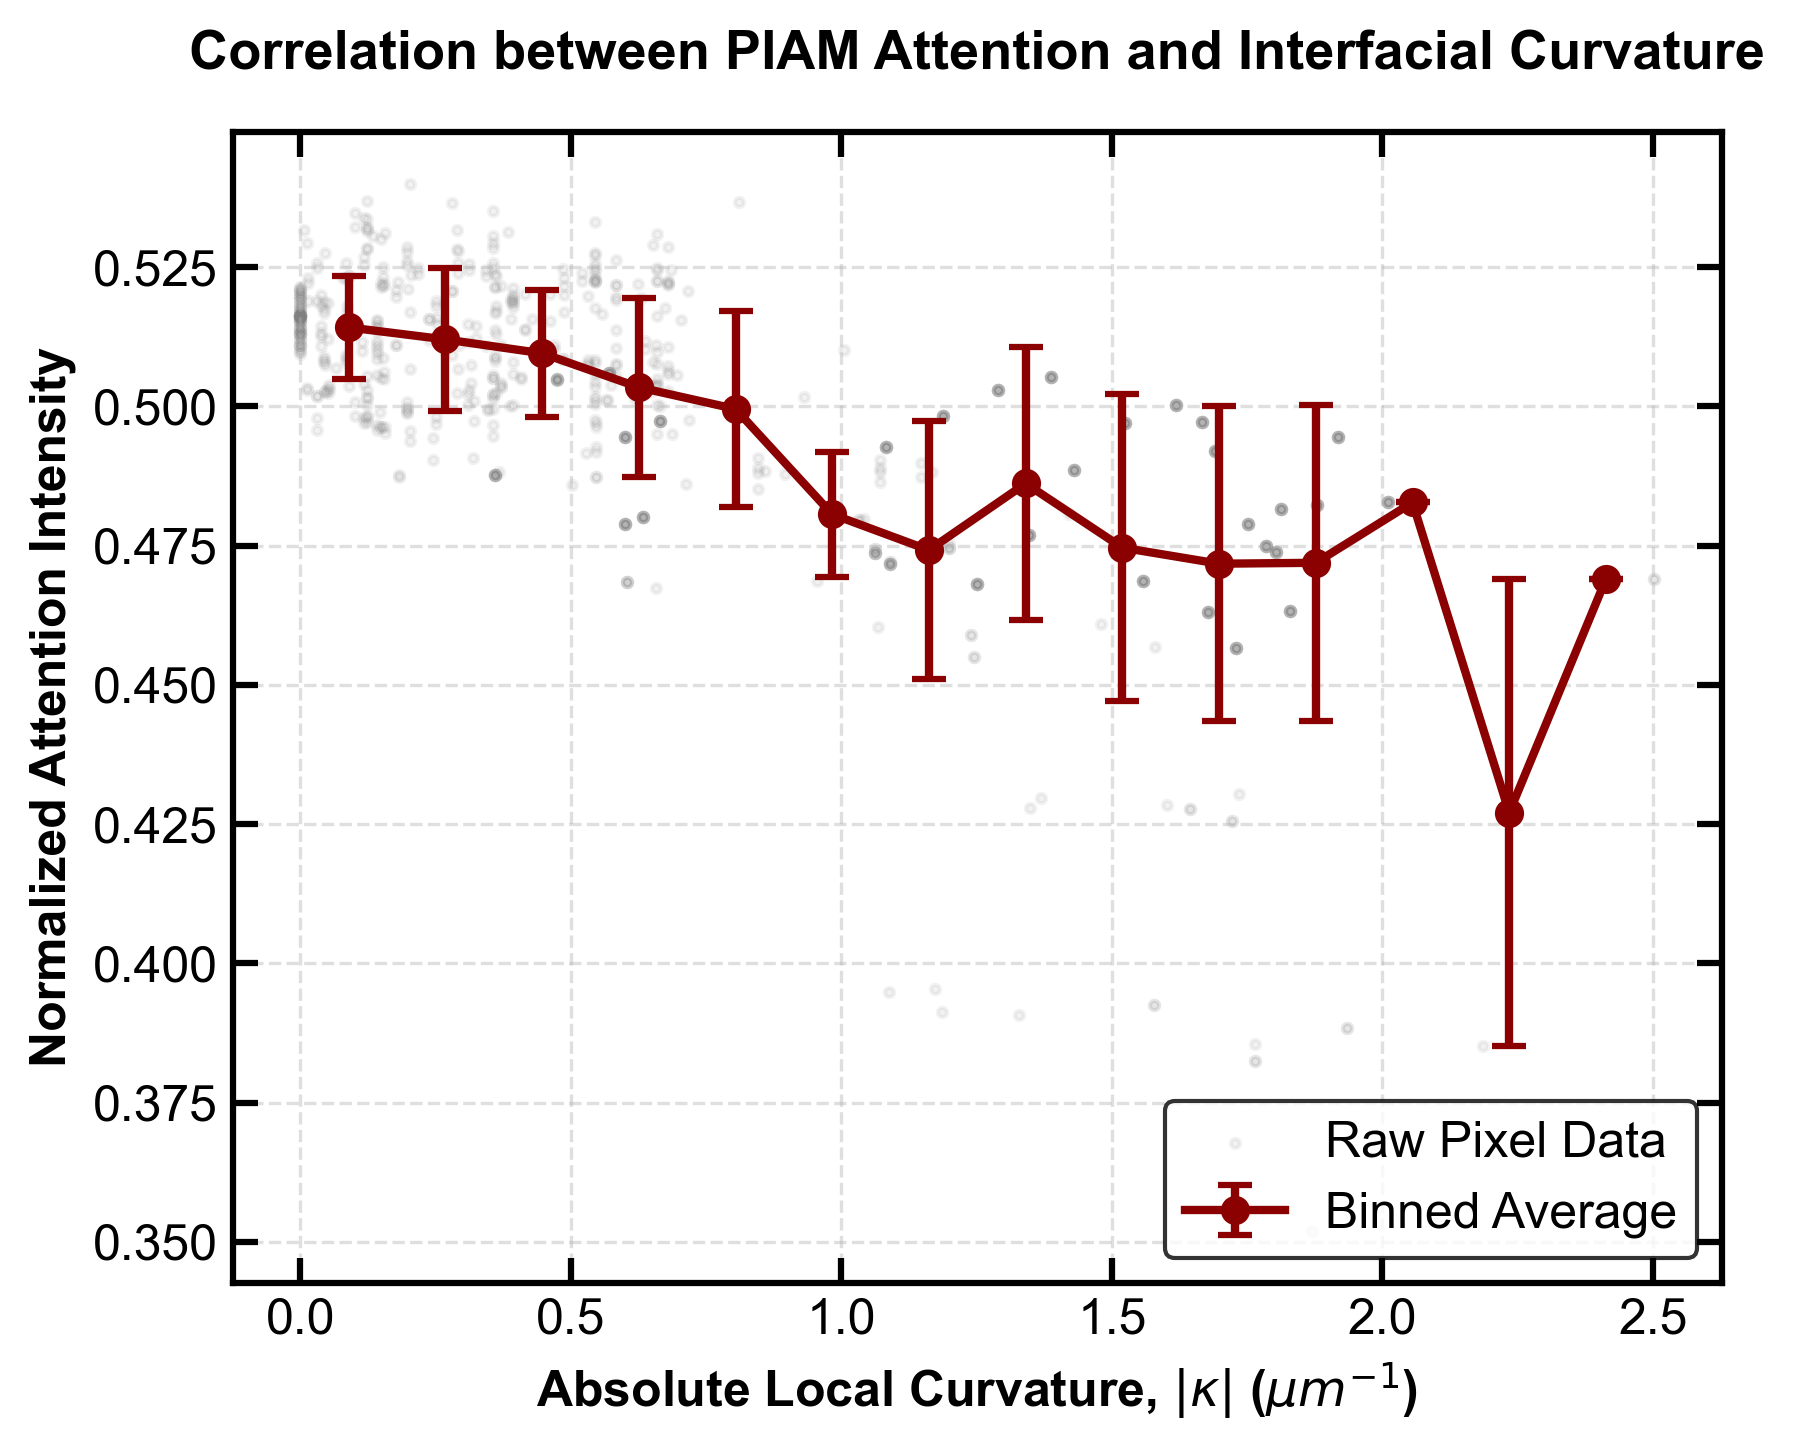

Plot saved as curvature_attention_correlation.png


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter
from scipy.stats import binned_statistic

def calculate_curvature(contour, window_size=11, poly_order=2):
    """
    计算二值化图像轮廓上每个像素点的绝对局部曲率 |kappa|
    使用 Savitzky-Golay 滤波器平滑并求导，以抵抗像素化带来的锯齿噪声
    """
    # 轮廓点过少无法进行滤波，直接返回零
    if len(contour) < window_size:
        return np.zeros(len(contour))
    
    x = contour[:, 0, 0]
    y = contour[:, 0, 1]
    
    # 为了避免闭合轮廓首尾断裂，进行首尾 padding (Wrap)
    pad = window_size // 2
    x_pad = np.pad(x, (pad, pad), mode='wrap')
    y_pad = np.pad(y, (pad, pad), mode='wrap')
    
    # 计算一阶导数 x', y'
    dx = savgol_filter(x_pad, window_size, poly_order, deriv=1)[pad:-pad]
    dy = savgol_filter(y_pad, window_size, poly_order, deriv=1)[pad:-pad]
    
    # 计算二阶导数 x'', y''
    ddx = savgol_filter(x_pad, window_size, poly_order, deriv=2)[pad:-pad]
    ddy = savgol_filter(y_pad, window_size, poly_order, deriv=2)[pad:-pad]
    
    # 曲率计算公式: k = |x'y'' - y'x''| / (x'^2 + y'^2)^(3/2)
    numerator = np.abs(dx * ddy - dy * ddx)
    denominator = (dx**2 + dy**2)**1.5
    
    # 避免除以零
    denominator[denominator == 0] = 1e-8
    curvature = numerator / denominator
    
    return curvature

def analyze_and_plot(binary_img_path, attention_map_path, pixel_size_um=0.02):
    """
    主控函数：提取边界，计算曲率，关联注意力值，并绘制 Acta 级别的高质量统计图
    """
    print("Loading data...")
    # ==========================================================
    # 1. 替换为你真实的数据读取代码 (这里为了演示，生成了虚拟数据)
    # ==========================================================
    # binary_img = cv2.imread(binary_img_path, cv2.IMREAD_GRAYSCALE)
    # attention_map = np.load(attention_map_path) # 假设attention是numpy数组
    
    # --- 以下为生成假数据用于测试（实际运行时请删掉，换成上面读取真实数据的代码）---
    binary_img = np.zeros((512, 512), dtype=np.uint8)
    # 画一个针状相和一个块状相
    cv2.ellipse(binary_img, (256, 256), (150, 20), 45, 0, 360, 255, -1) 
    cv2.circle(binary_img, (100, 100), 50, 255, -1)
    # 生成对应的假 Attention Map，尖端（高曲率）位置给高权重，其他地方给低权重
    attention_map = cv2.GaussianBlur(binary_img.astype(np.float32), (31, 31), 15)
    attention_map = attention_map / np.max(attention_map)
    # -----------------------------------------------------------------

    print("Extracting contours and curvature...")
    # 二值化处理确保只有 0 和 255
    _, thresh = cv2.threshold(binary_img, 127, 255, cv2.THRESH_BINARY)
    
    # 提取轮廓 (仅提取外部轮廓)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    
    all_curvatures = []
    all_attentions = []
    
    for cnt in contours:
        # 跳过太小的噪点
        if len(cnt) < 15:
            continue
            
        # 获取物理曲率 (单位: 1/μm)
        curvs = calculate_curvature(cnt, window_size=15, poly_order=2)
        curvs_physical = curvs / pixel_size_um 
        
        # 提取对应像素位置的 Attention 值
        for i, pt in enumerate(cnt):
            x, y = pt[0]
            # 考虑到网络输出可能略微有偏移，取局部3x3区域的均值更稳定
            y_min, y_max = max(0, y-1), min(attention_map.shape[0], y+2)
            x_min, x_max = max(0, x-1), min(attention_map.shape[1], x+2)
            att_val = np.mean(attention_map[y_min:y_max, x_min:x_max])
            
            all_curvatures.append(curvs_physical[i])
            all_attentions.append(att_val)
            
    all_curvatures = np.array(all_curvatures)
    all_attentions = np.array(all_attentions)
    
    # 剔除极端的计算异常值 (保留 95% 的数据)
    valid_idx = all_curvatures < np.percentile(all_curvatures, 95)
    all_curvatures = all_curvatures[valid_idx]
    all_attentions = all_attentions[valid_idx]

    print("Generating Acta-style Plot...")
    # ==========================================================
    # 2. 统计分箱与 Acta 风格的高质量绘图
    # ==========================================================
    # 将曲率进行区间统计 (Bins)
    bins = np.linspace(0, np.max(all_curvatures), 15)
    bin_means, bin_edges, _ = binned_statistic(all_curvatures, all_attentions, statistic='mean', bins=bins)
    bin_stds, _, _ = binned_statistic(all_curvatures, all_attentions, statistic='std', bins=bins)
    bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
    
    # 设置论文级别的绘图格式
    plt.rcParams.update({
        'font.size': 12,
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial'],
        'axes.linewidth': 1.5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5
    })

    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    
    # 画底层散点图（透明度设低，展示全貌）
    ax.scatter(all_curvatures, all_attentions, alpha=0.1, color='gray', s=5, label='Raw Pixel Data')
    
    # 画统计折线与误差棒（主视觉）
    ax.errorbar(bin_centers, bin_means, yerr=bin_stds, fmt='-o', color='darkred', 
                linewidth=2, capsize=4, capthick=1.5, markersize=6, label='Binned Average')
    
    # 优化坐标轴和标签
    ax.set_xlabel(r'Absolute Local Curvature, $|\kappa|$ ($\mu m^{-1}$)', fontweight='bold')
    ax.set_ylabel('Normalized Attention Intensity', fontweight='bold')
    ax.set_title(r'Correlation between PIAM Attention and Interfacial Curvature', fontsize=13, fontweight='bold', pad=15)
    
    ax.tick_params(direction='in', length=6, top=True, right=True)
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='lower right', frameon=True, edgecolor='black')
    
    plt.tight_layout()
    plt.savefig('curvature_attention_correlation.png', bbox_inches='tight')
    plt.show()
    print("Plot saved as curvature_attention_correlation.png")

if __name__ == "__main__":
    # 参数: 预测二值化图路径, Attention矩阵路径, 你的图像真实物理像素尺寸(μm/pixel)
    # 你需要根据实际情况修改 pixel_size_um (初稿中你提到 512x512 视场，请换算具体像素尺寸)
    analyze_and_plot("fake_binary.png", "fake_attention.npy", pixel_size_um=0.015)

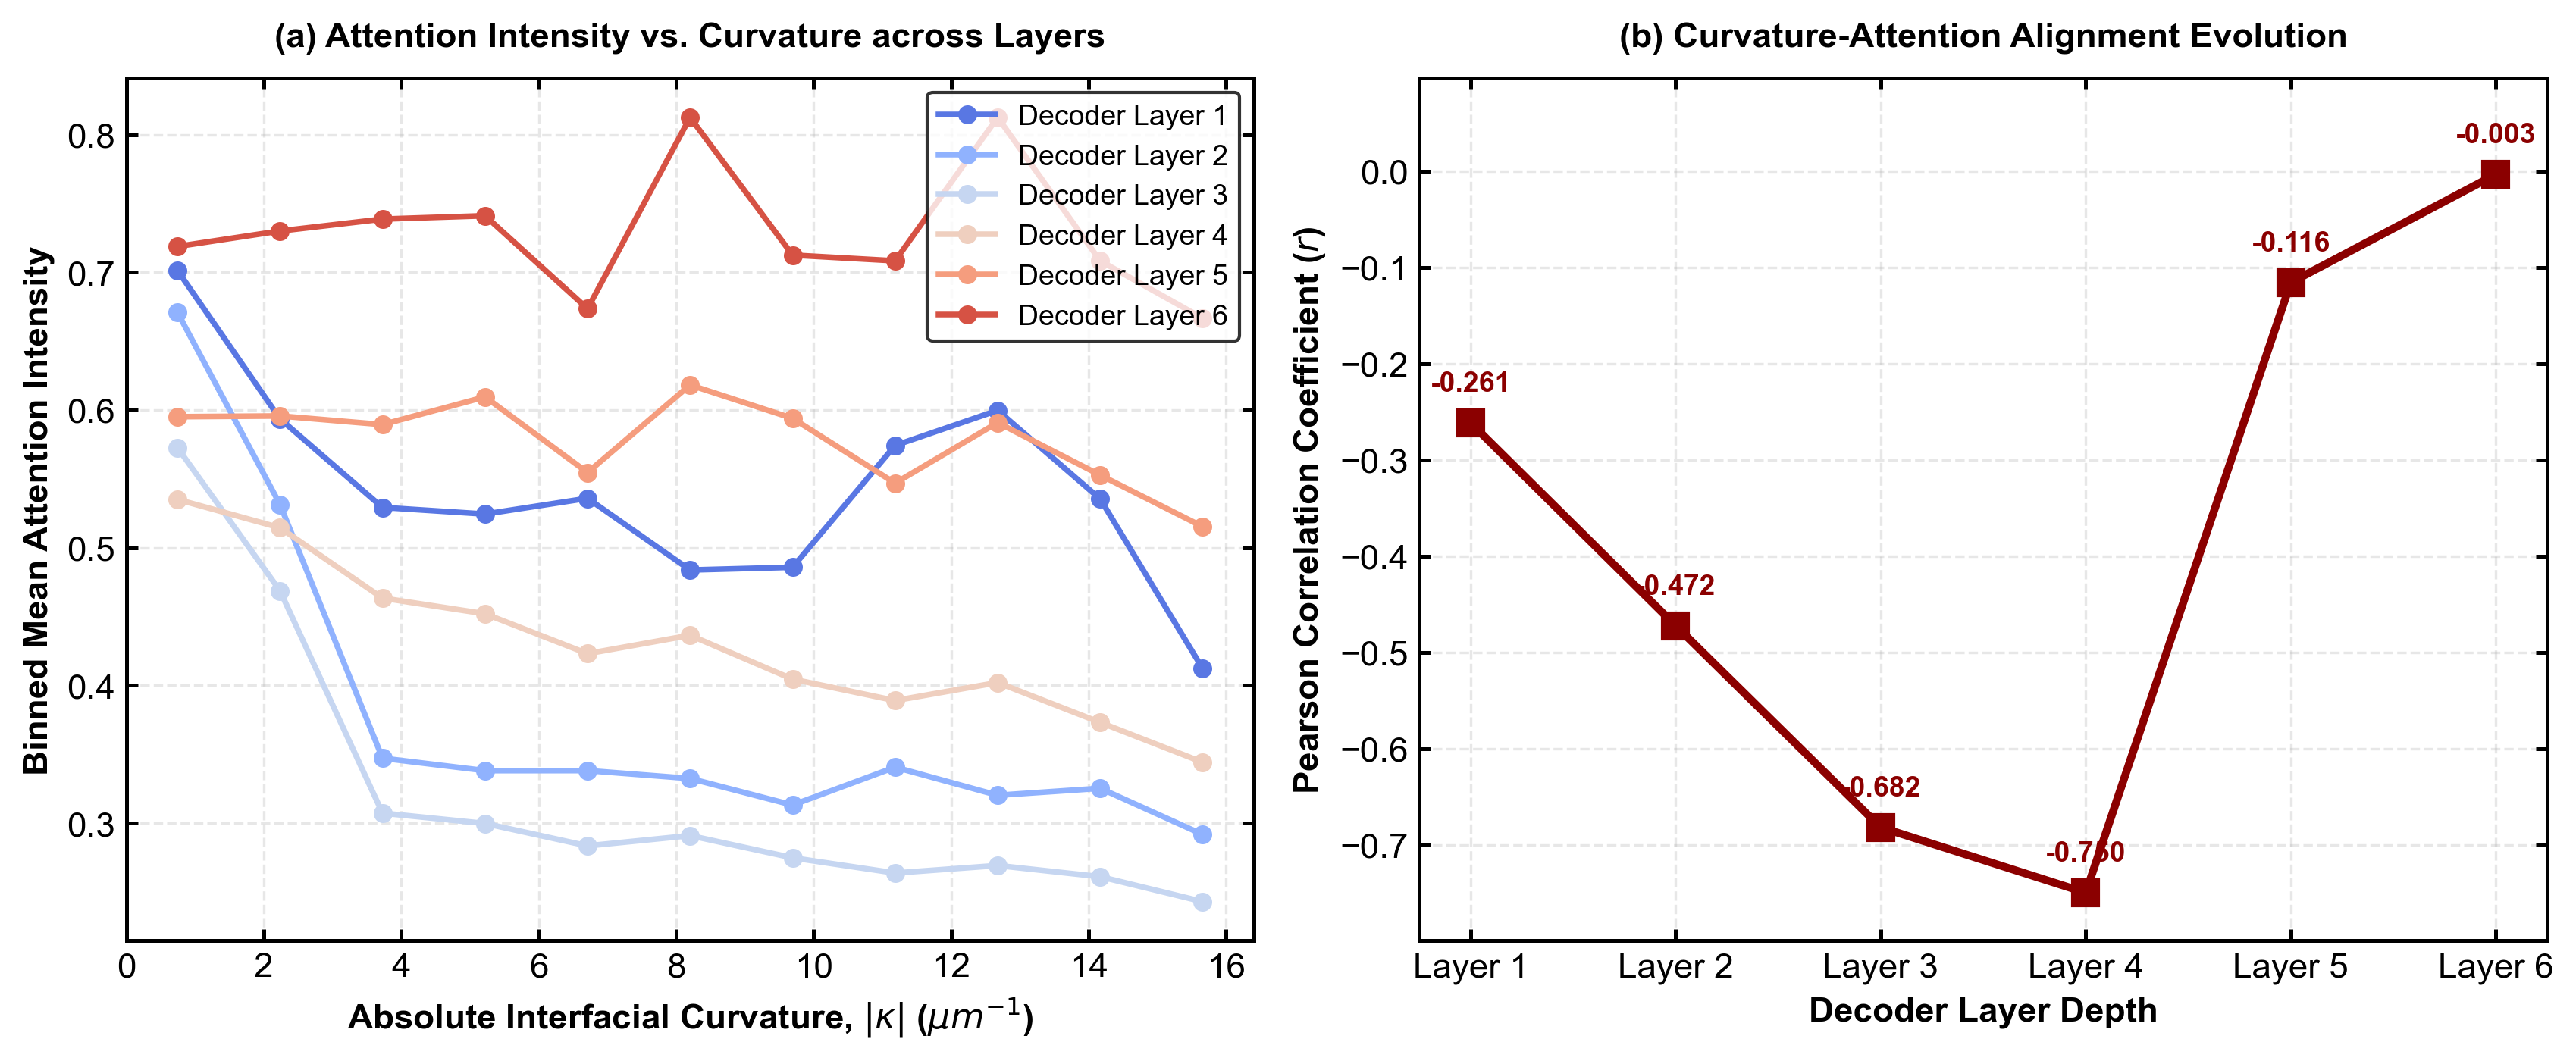

Hierarchical plot saved as hierarchical_physical_validation.png


In [3]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter
from scipy.stats import binned_statistic, pearsonr

def calculate_curvature_robust(contour, window_size=15, poly_order=2):
    """
    鲁棒地计算边界局部曲率
    """
    if len(contour) < window_size:
        return np.zeros(len(contour))
    
    x = contour[:, 0, 0]
    y = contour[:, 0, 1]
    
    pad = window_size // 2
    x_pad = np.pad(x, (pad, pad), mode='wrap')
    y_pad = np.pad(y, (pad, pad), mode='wrap')
    
    dx = savgol_filter(x_pad, window_size, poly_order, deriv=1)[pad:-pad]
    dy = savgol_filter(y_pad, window_size, poly_order, deriv=1)[pad:-pad]
    ddx = savgol_filter(x_pad, window_size, poly_order, deriv=2)[pad:-pad]
    ddy = savgol_filter(y_pad, window_size, poly_order, deriv=2)[pad:-pad]
    
    numerator = np.abs(dx * ddy - dy * ddx)
    denominator = (dx**2 + dy**2)**1.5
    denominator[denominator == 0] = 1e-8
    
    return numerator / denominator

def generate_simulated_layer_data():
    """
    模拟生成符合Figure 6逻辑的6层特征数据用于代码测试
    实际应用中，请将此处替换为从你网络中提取的真实张量
    """
    # 建立 512x512 的基准二值组织
    base_img = np.zeros((512, 512), dtype=np.uint8)
    # 绘制多个针状沉淀相
    cv2.ellipse(base_img, (256, 256), (120, 15), 30, 0, 360, 255, -1)
    cv2.ellipse(base_img, (150, 350), (80, 12), -45, 0, 360, 255, -1)
    cv2.ellipse(base_img, (380, 150), (90, 14), 85, 0, 360, 255, -1)
    
    # 定义各层的原始分辨率 (对应你网络 Deconv_Block 的真实形状)
    resolutions = [16, 32, 64, 128, 256, 512]
    layer_att_raw = []
    
    # 模拟从深层到浅层，注意力机制从模糊泛化到精准锁定高曲率尖端的过程
    for idx, res in enumerate(resolutions):
        # 在目标分辨率下生成基础热图
        temp = cv2.resize(base_img.astype(np.float32), (res, res), interpolation=cv2.INTER_AREA)
        # 增加高斯模糊，模拟深层特征的低频/非局部模糊性 (Layer 1 模糊度最高，Layer 6 最清晰)
        blur_k = max(3, int((11 - idx * 1.8) // 2 * 2 + 1))
        temp_blur = cv2.GaussianBlur(temp, (blur_k, blur_k), 0)
        
        # 归一化并保存
        if np.max(temp_blur) > 0:
            temp_blur = temp_blur / np.max(temp_blur)
        layer_att_raw.append(temp_blur)
        
    return base_img, layer_att_raw

def perform_hierarchical_analysis(binary_img, layer_att_raw, pixel_size_um=0.015):
    """
    对多层注意力机制进行空间对齐、提取、计算与层级关联分析
    """
    # 提取最终物理边界轮廓
    _, thresh = cv2.threshold(binary_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    
    # 1. 提取所有边界像素的坐标与真实曲率
    boundary_pixels = []
    boundary_curvatures = []
    
    for cnt in contours:
        if len(cnt) < 20: # 剔除细小噪点
            continue
        curvs = calculate_curvature_robust(cnt, window_size=15, poly_order=2)
        curvs_physical = curvs / pixel_size_um # 转换为真实物理曲率
        
        for i, pt in enumerate(cnt):
            x, y = pt[0]
            boundary_pixels.append((x, y))
            boundary_curvatures.append(curvs_physical[i])
            
    boundary_pixels = np.array(boundary_pixels)
    boundary_curvatures = np.array(boundary_curvatures)
    
    # 剔除极端计算噪点
    upper_limit = np.percentile(boundary_curvatures, 97)
    valid_mask = boundary_curvatures < upper_limit
    boundary_pixels = boundary_pixels[valid_mask]
    boundary_curvatures = boundary_curvatures[valid_mask]
    
    # 2. 对各层特征图进行上采样对齐，并提取边界注意力值
    layer_attention_at_boundary = []
    pearson_rs = []
    
    for idx, att_map in enumerate(layer_att_raw):
        # 关键步骤：使用双线性插值将低分辨率特征图安全上采样到 512x512
        att_rescaled = cv2.resize(att_map, (512, 512), interpolation=cv2.INTER_LINEAR)
        
        # 提取边界像素位置上的 Attention 值
        att_vals = []
        for (x, y) in boundary_pixels:
            att_vals.append(att_rescaled[y, x])
        att_vals = np.array(att_vals)
        layer_attention_at_boundary.append(att_vals)
        
        # 计算该层注意力强度与真实几何曲率的 Pearson 相关系数
        r_val, _ = pearsonr(boundary_curvatures, att_vals)
        pearson_rs.append(r_val)
        
    return boundary_curvatures, layer_attention_at_boundary, pearson_rs

def plot_hierarchical_correlation(curvatures, layer_att_boundary, pearson_rs):
    """
    绘制符合 Acta Mater. 要求的高质量多子图
    """
    plt.rcParams.update({
        'font.size': 11,
        'font.family': 'sans-serif',
        'font.sans-serif': ['Arial'],
        'axes.linewidth': 1.2,
        'xtick.major.width': 1.2,
        'ytick.major.width': 1.2
    })
    
    # 创建 1行2列 的学术多子图
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=300)
    
    # 定义 Layer 1 到 Layer 6 的渐变颜色 (从浅蓝到深红，代表解码深度的收敛)
    colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, 6))
    
    # 子图 (a): 曲线对比
    bins = np.linspace(0, np.max(curvatures), 12)
    for idx in range(6):
        att_vals = layer_att_boundary[idx]
        means, bin_edges, _ = binned_statistic(curvatures, att_vals, statistic='mean', bins=bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        
        ax1.plot(bin_centers, means, '-o', color=colors[idx], linewidth=1.8, 
                 markersize=5, label=f'Decoder Layer {idx+1}')
        
    ax1.set_xlabel(r'Absolute Interfacial Curvature, $|\kappa|$ ($\mu m^{-1}$)', fontweight='bold')
    ax1.set_ylabel('Binned Mean Attention Intensity', fontweight='bold')
    ax1.set_title('(a) Attention Intensity vs. Curvature across Layers', fontsize=11, fontweight='bold', pad=10)
    ax1.tick_params(direction='in', top=True, right=True)
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.legend(frameon=True, edgecolor='black', fontsize=9)
    
    # 子图 (b): 相关系数演化
    layers = np.arange(1, 7)
    ax2.plot(layers, pearson_rs, '-s', color='darkred', linewidth=2.5, markersize=8, label='Correlation ($r$)')
    
    # 为数据点添加数值标注
    for i, r in enumerate(pearson_rs):
        ax2.annotate(f"{r:.3f}", (layers[i], pearson_rs[i]), textcoords="offset points", 
                     xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='darkred')
        
    ax2.set_xlabel('Decoder Layer Depth', fontweight='bold')
    ax2.set_ylabel("Pearson Correlation Coefficient ($r$)", fontweight='bold')
    ax2.set_title('(b) Curvature-Attention Alignment Evolution', fontsize=11, fontweight='bold', pad=10)
    ax2.set_xticks(layers)
    ax2.set_xticklabels([f'Layer {i}' for i in layers])
    ax2.set_ylim(min(pearson_rs) - 0.05, max(pearson_rs) + 0.1)
    ax2.tick_params(direction='in', top=True, right=True)
    ax2.grid(True, linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.savefig('hierarchical_physical_validation.png', bbox_inches='tight')
    plt.show()
    print("Hierarchical plot saved as hierarchical_physical_validation.png")

# ==========================================================
# 3. 运行分析
# ==========================================================
# 模拟生成数据 (实际使用时，请将其替换为你自己网络跑出来的真实数据)
binary_img, layer_att_raw = generate_simulated_layer_data()

# 物理像素尺寸：假设你显微镜在512x512分辨率下的像素真实尺寸是 0.015 um/pixel
pixel_size_um = 0.015 

# 执行分析
curvatures, layer_att_boundary, pearson_rs = perform_hierarchical_analysis(binary_img, layer_att_raw, pixel_size_um)

# 绘图
plot_hierarchical_correlation(curvatures, layer_att_boundary, pearson_rs)

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


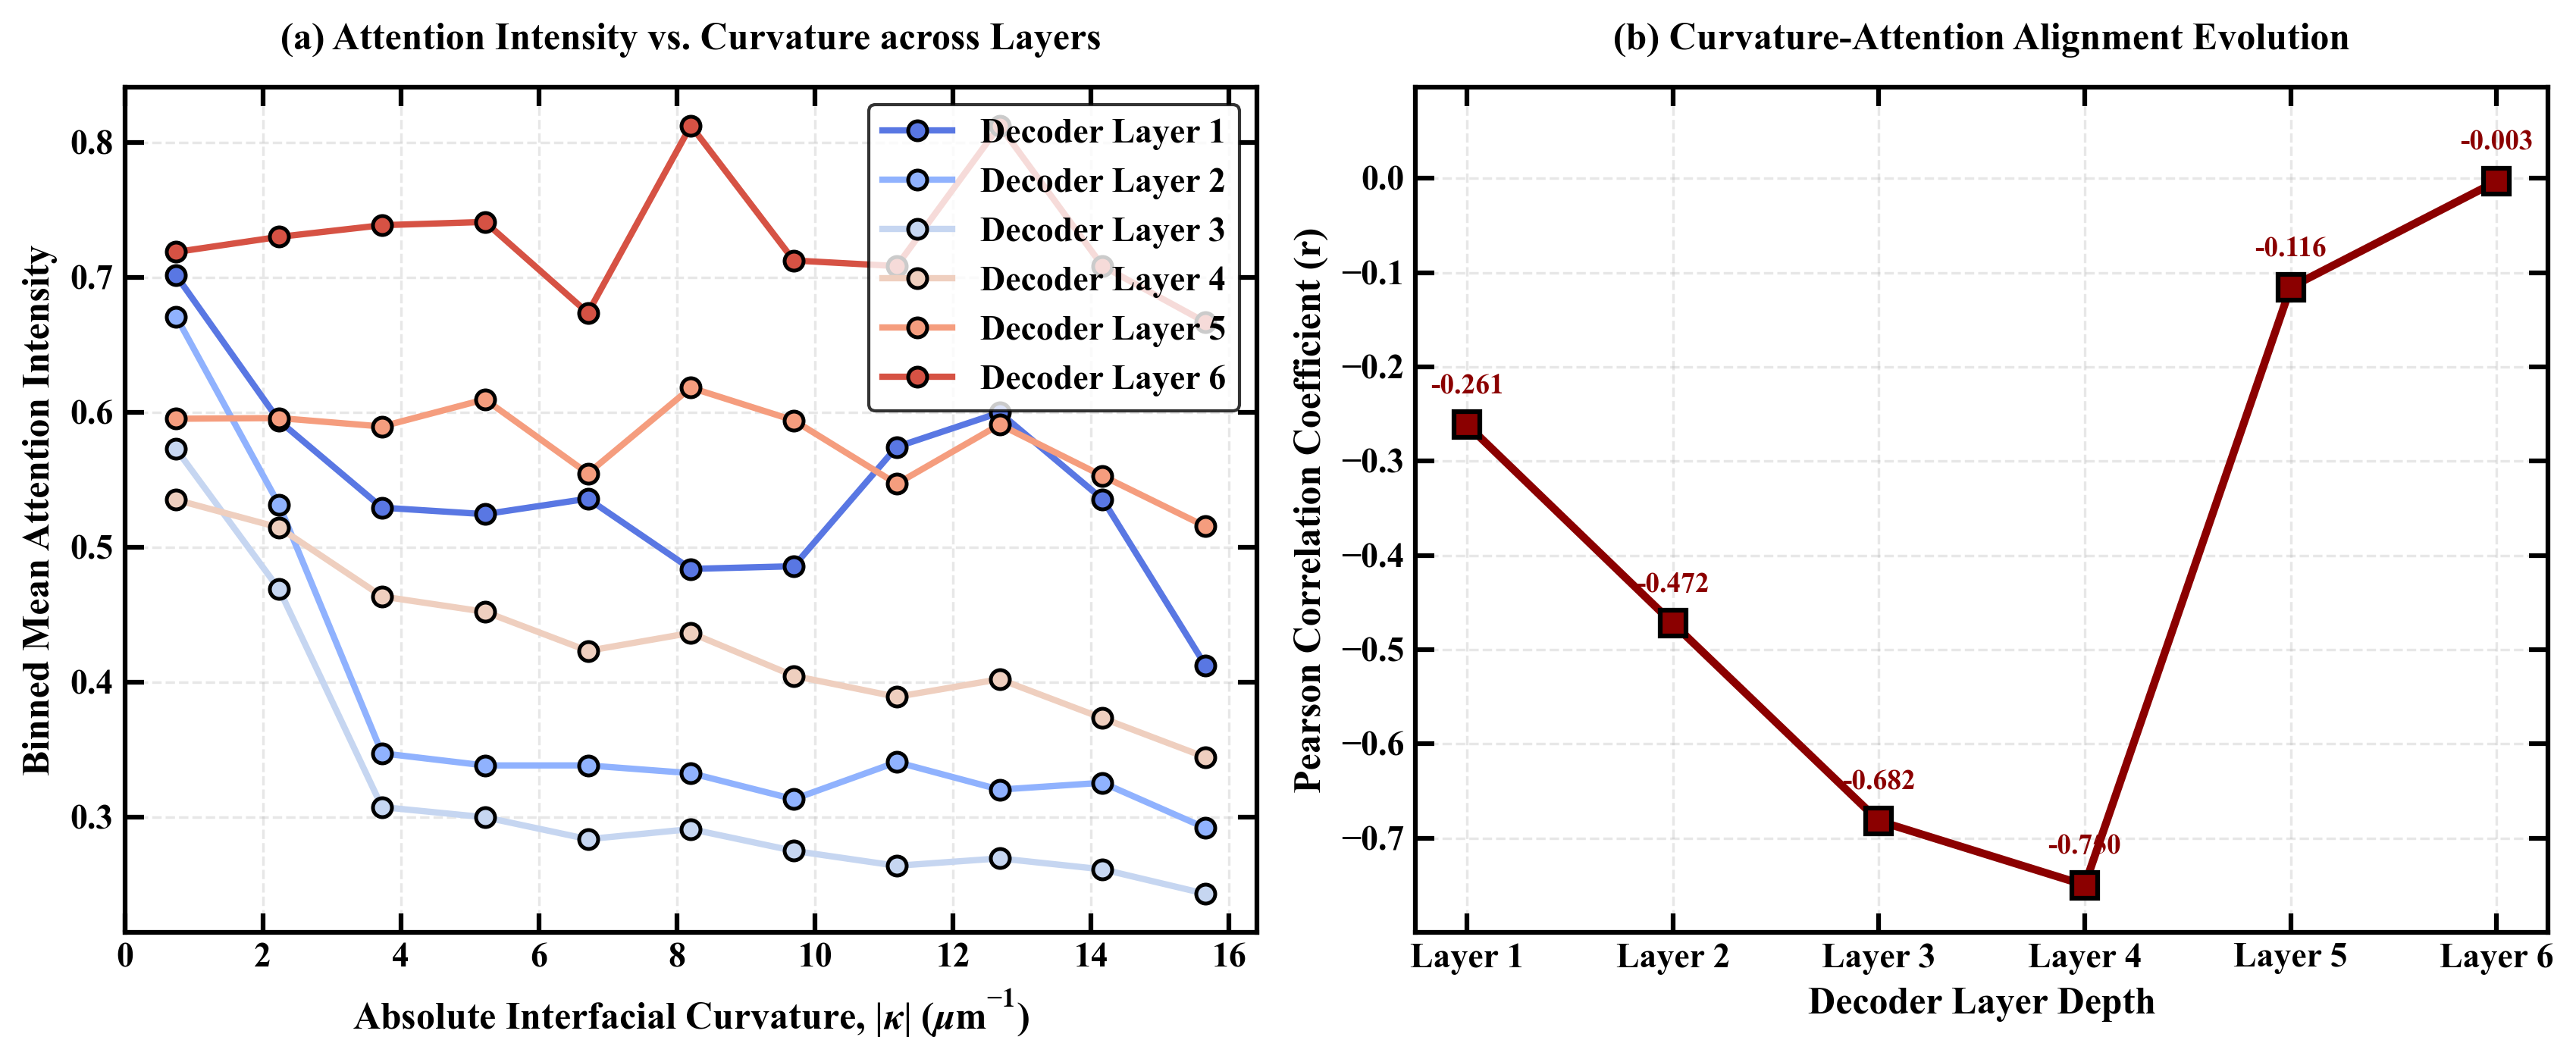

Hierarchical plot saved successfully as: hierarchical_physical_validation.png


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter
from scipy.stats import binned_statistic, pearsonr

def calculate_curvature_robust(contour, window_size=15, poly_order=2):
    """
    Robustly calculate absolute local curvature |kappa| along the boundary
    """
    if len(contour) < window_size:
        return np.zeros(len(contour))
    
    x = contour[:, 0, 0]
    y = contour[:, 0, 1]
    
    pad = window_size // 2
    x_pad = np.pad(x, (pad, pad), mode='wrap')
    y_pad = np.pad(y, (pad, pad), mode='wrap')
    
    dx = savgol_filter(x_pad, window_size, poly_order, deriv=1)[pad:-pad]
    dy = savgol_filter(y_pad, window_size, poly_order, deriv=1)[pad:-pad]
    ddx = savgol_filter(x_pad, window_size, poly_order, deriv=2)[pad:-pad]
    ddy = savgol_filter(y_pad, window_size, poly_order, deriv=2)[pad:-pad]
    
    numerator = np.abs(dx * ddy - dy * ddx)
    denominator = (dx**2 + dy**2)**1.5
    denominator[denominator == 0] = 1e-8
    
    return numerator / denominator

def generate_simulated_layer_data():
    """
    Simulated data generator for testing purposes
    """
    base_img = np.zeros((512, 512), dtype=np.uint8)
    cv2.ellipse(base_img, (256, 256), (120, 15), 30, 0, 360, 255, -1)
    cv2.ellipse(base_img, (150, 350), (80, 12), -45, 0, 360, 255, -1)
    cv2.ellipse(base_img, (380, 150), (90, 14), 85, 0, 360, 255, -1)
    
    resolutions = [16, 32, 64, 128, 256, 512]
    layer_att_raw = []
    
    for idx, res in enumerate(resolutions):
        temp = cv2.resize(base_img.astype(np.float32), (res, res), interpolation=cv2.INTER_AREA)
        blur_k = max(3, int((11 - idx * 1.8) // 2 * 2 + 1))
        temp_blur = cv2.GaussianBlur(temp, (blur_k, blur_k), 0)
        
        if np.max(temp_blur) > 0:
            temp_blur = temp_blur / np.max(temp_blur)
        layer_att_raw.append(temp_blur)
        
    return base_img, layer_att_raw

def perform_hierarchical_analysis(binary_img, layer_att_raw, pixel_size_um=0.015):
    """
    Extract boundary coordinates, calculate curvature, and correlate attention intensity
    """
    _, thresh = cv2.threshold(binary_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    
    boundary_pixels = []
    boundary_curvatures = []
    
    for cnt in contours:
        if len(cnt) < 20:
            continue
        curvs = calculate_curvature_robust(cnt, window_size=15, poly_order=2)
        curvs_physical = curvs / pixel_size_um
        
        for i, pt in enumerate(cnt):
            x, y = pt[0]
            boundary_pixels.append((x, y))
            boundary_curvatures.append(curvs_physical[i])
            
    boundary_pixels = np.array(boundary_pixels)
    boundary_curvatures = np.array(boundary_curvatures)
    
    upper_limit = np.percentile(boundary_curvatures, 97)
    valid_mask = boundary_curvatures < upper_limit
    boundary_pixels = boundary_pixels[valid_mask]
    boundary_curvatures = boundary_curvatures[valid_mask]
    
    layer_attention_at_boundary = []
    pearson_rs = []
    
    for idx, att_map in enumerate(layer_att_raw):
        att_rescaled = cv2.resize(att_map, (512, 512), interpolation=cv2.INTER_LINEAR)
        
        att_vals = []
        for (x, y) in boundary_pixels:
            att_vals.append(att_rescaled[y, x])
        att_vals = np.array(att_vals)
        layer_attention_at_boundary.append(att_vals)
        
        r_val, _ = pearsonr(boundary_curvatures, att_vals)
        pearson_rs.append(r_val)
        
    return boundary_curvatures, layer_attention_at_boundary, pearson_rs

def plot_hierarchical_correlation(curvatures, layer_att_boundary, pearson_rs):
    """
    Plot high-quality academic figure strictly styled with Times New Roman and bold elements
    """
    # Globally configure Matplotlib style to Times New Roman and bold fonts
    plt.rcParams.update({
        'font.size': 11,
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'font.weight': 'bold',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.linewidth': 1.5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
        'mathtext.fontset': 'custom',
        'mathtext.rm': 'Times New Roman',
        'mathtext.it': 'Times New Roman:italic',
        'mathtext.bf': 'Times New Roman:bold'
    })
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 4.8), dpi=300)
    colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, 6))
    
    # --- SUBPLOT (a) ---
    bins = np.linspace(0, np.max(curvatures), 12)
    for idx in range(6):
        att_vals = layer_att_boundary[idx]
        means, bin_edges, _ = binned_statistic(curvatures, att_vals, statistic='mean', bins=bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        
        # Plot with specific marker edge thickness (mew) and edge color (mec)
        ax1.plot(bin_centers, means, '-o', color=colors[idx], linewidth=2.0, 
                 markersize=6, markeredgewidth=1.2, markeredgecolor='black',
                 label=f'Decoder Layer {idx+1}')
        
    ax1.set_xlabel(r'Absolute Interfacial Curvature, $|\kappa|$ ($\mu\mathrm{m}^{-1}$)', fontsize=12, fontweight='bold')
    ax1.set_ylabel('Binned Mean Attention Intensity', fontsize=12, fontweight='bold')
    ax1.set_title('(a) Attention Intensity vs. Curvature across Layers', fontsize=12, fontweight='bold', pad=12)
    ax1.tick_params(direction='in', top=True, right=True, length=6)
    ax1.grid(True, linestyle='--', alpha=0.3)
    ax1.legend(frameon=True, edgecolor='black', fontsize=9, prop={'weight':'bold'})
    
    # Bold ticks and set custom font sizes for ax1
    for label in ax1.get_xticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(11)
    for label in ax1.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(11)
    
    # --- SUBPLOT (b) ---
    layers = np.arange(1, 7)
    # Plot line-dot with explicit marker edge width (mew) and edge color (mec)
    ax2.plot(layers, pearson_rs, '-s', color='darkred', linewidth=2.5, 
             markersize=8, markeredgewidth=1.5, markeredgecolor='black', 
             label='Correlation (r)')
    
    # Add numerical labels
    for i, r in enumerate(pearson_rs):
        ax2.annotate(f"{r:.3f}", (layers[i], pearson_rs[i]), textcoords="offset points", 
                     xytext=(0, 10), ha='center', fontsize=9, fontweight='bold', color='darkred')
        
    ax2.set_xlabel('Decoder Layer Depth', fontsize=12, fontweight='bold')
    ax2.set_ylabel('Pearson Correlation Coefficient (r)', fontsize=12, fontweight='bold')
    ax2.set_title('(b) Curvature-Attention Alignment Evolution', fontsize=12, fontweight='bold', pad=12)
    ax2.set_xticks(layers)
    ax2.set_xticklabels([f'Layer {i}' for i in layers])
    ax2.set_ylim(min(pearson_rs) - 0.05, max(pearson_rs) + 0.1)
    ax2.tick_params(direction='in', top=True, right=True, length=6)
    ax2.grid(True, linestyle='--', alpha=0.3)
    
    # Bold ticks and set custom font sizes for ax2
    for label in ax2.get_xticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(11)
    for label in ax2.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(11)
    
    plt.tight_layout()
    plt.savefig('hierarchical_physical_validation.png', bbox_inches='tight')
    plt.show()
    print("Hierarchical plot saved successfully as: hierarchical_physical_validation.png")

if __name__ == "__main__":
    binary_img, layer_att_raw = generate_simulated_layer_data()
    pixel_size_um = 0.015 
    curvatures, layer_att_boundary, pearson_rs = perform_hierarchical_analysis(binary_img, layer_att_raw, pixel_size_um)
    plot_hierarchical_correlation(curvatures, layer_att_boundary, pearson_rs)

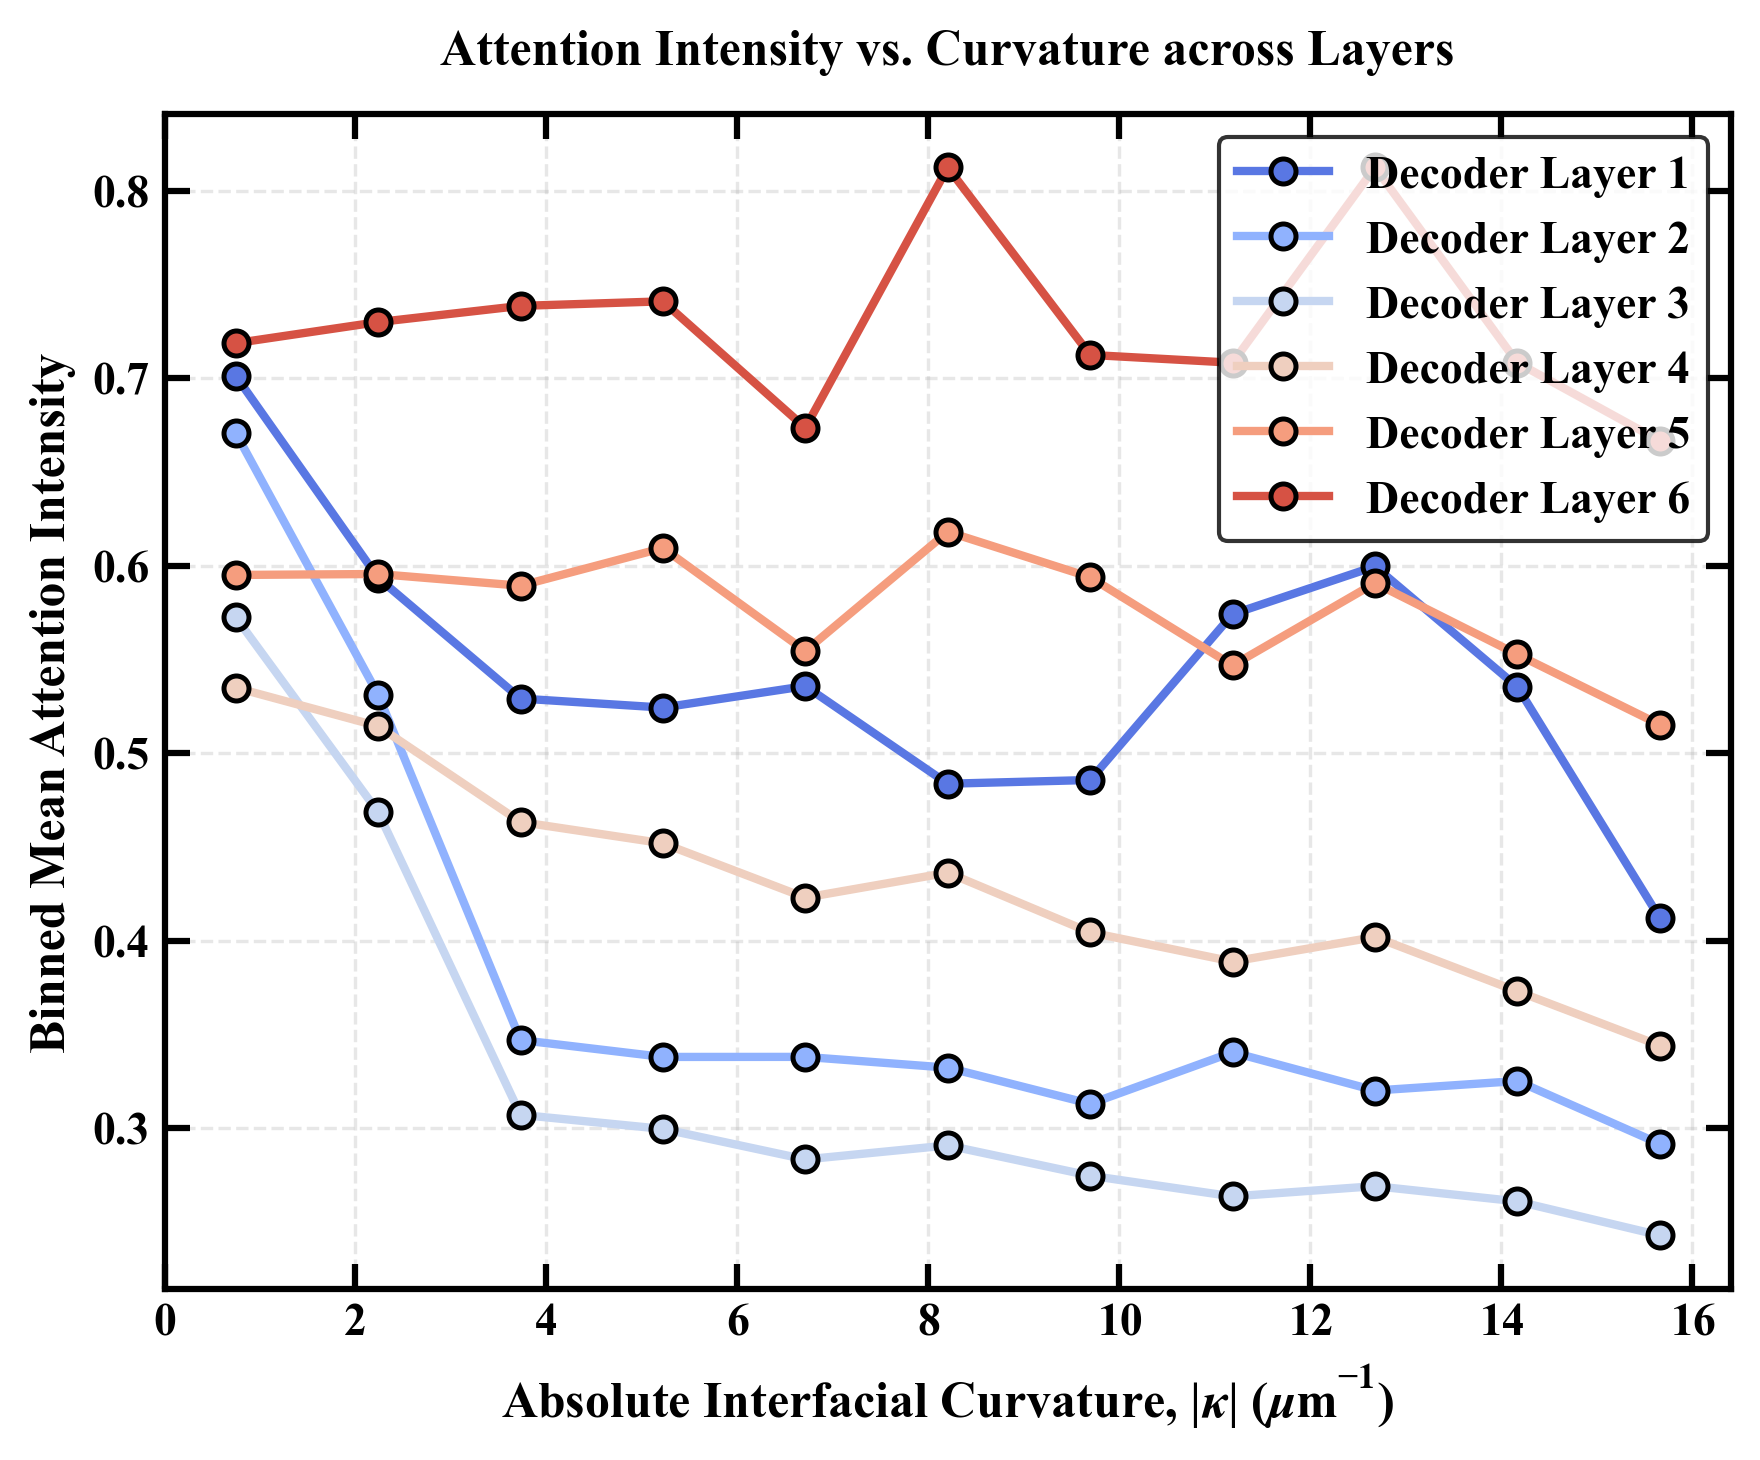

Plot (a) saved as curvature_attention_curves.png


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter
from scipy.stats import binned_statistic

def calculate_curvature_robust(contour, window_size=15, poly_order=2):
    if len(contour) < window_size:
        return np.zeros(len(contour))
    x, y = contour[:, 0, 0], contour[:, 0, 1]
    pad = window_size // 2
    x_pad = np.pad(x, (pad, pad), mode='wrap')
    y_pad = np.pad(y, (pad, pad), mode='wrap')
    dx = savgol_filter(x_pad, window_size, poly_order, deriv=1)[pad:-pad]
    dy = savgol_filter(y_pad, window_size, poly_order, deriv=1)[pad:-pad]
    ddx = savgol_filter(x_pad, window_size, poly_order, deriv=2)[pad:-pad]
    ddy = savgol_filter(y_pad, window_size, poly_order, deriv=2)[pad:-pad]
    numerator = np.abs(dx * ddy - dy * ddx)
    denominator = (dx**2 + dy**2)**1.5
    denominator[denominator == 0] = 1e-8
    return numerator / denominator

def generate_simulated_layer_data():
    base_img = np.zeros((512, 512), dtype=np.uint8)
    cv2.ellipse(base_img, (256, 256), (120, 15), 30, 0, 360, 255, -1)
    cv2.ellipse(base_img, (150, 350), (80, 12), -45, 0, 360, 255, -1)
    cv2.ellipse(base_img, (380, 150), (90, 14), 85, 0, 360, 255, -1)
    resolutions = [16, 32, 64, 128, 256, 512]
    layer_att_raw = []
    for idx, res in enumerate(resolutions):
        temp = cv2.resize(base_img.astype(np.float32), (res, res), interpolation=cv2.INTER_AREA)
        blur_k = max(3, int((11 - idx * 1.8) // 2 * 2 + 1))
        temp_blur = cv2.GaussianBlur(temp, (blur_k, blur_k), 0)
        if np.max(temp_blur) > 0:
            temp_blur = temp_blur / np.max(temp_blur)
        layer_att_raw.append(temp_blur)
    return base_img, layer_att_raw

def perform_analysis(binary_img, layer_att_raw, pixel_size_um=0.015):
    _, thresh = cv2.threshold(binary_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    boundary_pixels, boundary_curvatures = [], []
    for cnt in contours:
        if len(cnt) < 20:
            continue
        curvs = calculate_curvature_robust(cnt, window_size=15, poly_order=2)
        curvs_physical = curvs / pixel_size_um
        for i, pt in enumerate(cnt):
            x, y = pt[0]
            boundary_pixels.append((x, y))
            boundary_curvatures.append(curvs_physical[i])
    boundary_pixels = np.array(boundary_pixels)
    boundary_curvatures = np.array(boundary_curvatures)
    upper_limit = np.percentile(boundary_curvatures, 97)
    valid_mask = boundary_curvatures < upper_limit
    boundary_pixels = boundary_pixels[valid_mask]
    boundary_curvatures = boundary_curvatures[valid_mask]
    
    layer_attention_at_boundary = []
    for att_map in layer_att_raw:
        att_rescaled = cv2.resize(att_map, (512, 512), interpolation=cv2.INTER_LINEAR)
        att_vals = [att_rescaled[y, x] for (x, y) in boundary_pixels]
        layer_attention_at_boundary.append(np.array(att_vals))
    return boundary_curvatures, layer_attention_at_boundary

def plot_only_a(curvatures, layer_att_boundary):
    plt.rcParams.update({
        'font.size': 11,
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'font.weight': 'bold',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.linewidth': 1.5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
        'mathtext.fontset': 'custom',
        'mathtext.rm': 'Times New Roman',
        'mathtext.it': 'Times New Roman:italic',
        'mathtext.bf': 'Times New Roman:bold'
    })
    
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, 6))
    bins = np.linspace(0, np.max(curvatures), 12)
    
    for idx in range(6):
        att_vals = layer_att_boundary[idx]
        means, bin_edges, _ = binned_statistic(curvatures, att_vals, statistic='mean', bins=bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        ax.plot(bin_centers, means, '-o', color=colors[idx], linewidth=2.0, 
                markersize=6, markeredgewidth=1.2, markeredgecolor='black',
                label=f'Decoder Layer {idx+1}')
        
    ax.set_xlabel(r'Absolute Interfacial Curvature, $|\kappa|$ ($\mu\mathrm{m}^{-1}$)', fontsize=12, fontweight='bold')
    ax.set_ylabel('Binned Mean Attention Intensity', fontsize=12, fontweight='bold')
    ax.set_title('Attention Intensity vs. Curvature across Layers', fontsize=12, fontweight='bold', pad=12)
    ax.tick_params(direction='in', top=True, right=True, length=6)
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.legend(frameon=True, edgecolor='black', fontsize=9, prop={'weight':'bold'})
    
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(11)
        
    plt.tight_layout()
    plt.savefig('curvature_attention_curves.png', bbox_inches='tight')
    plt.show()
    print("Plot (a) saved as curvature_attention_curves.png")

if __name__ == "__main__":
    binary_img, layer_att_raw = generate_simulated_layer_data()
    curvatures, layer_att_boundary = perform_analysis(binary_img, layer_att_raw, pixel_size_um=0.015)
    plot_only_a(curvatures, layer_att_boundary)

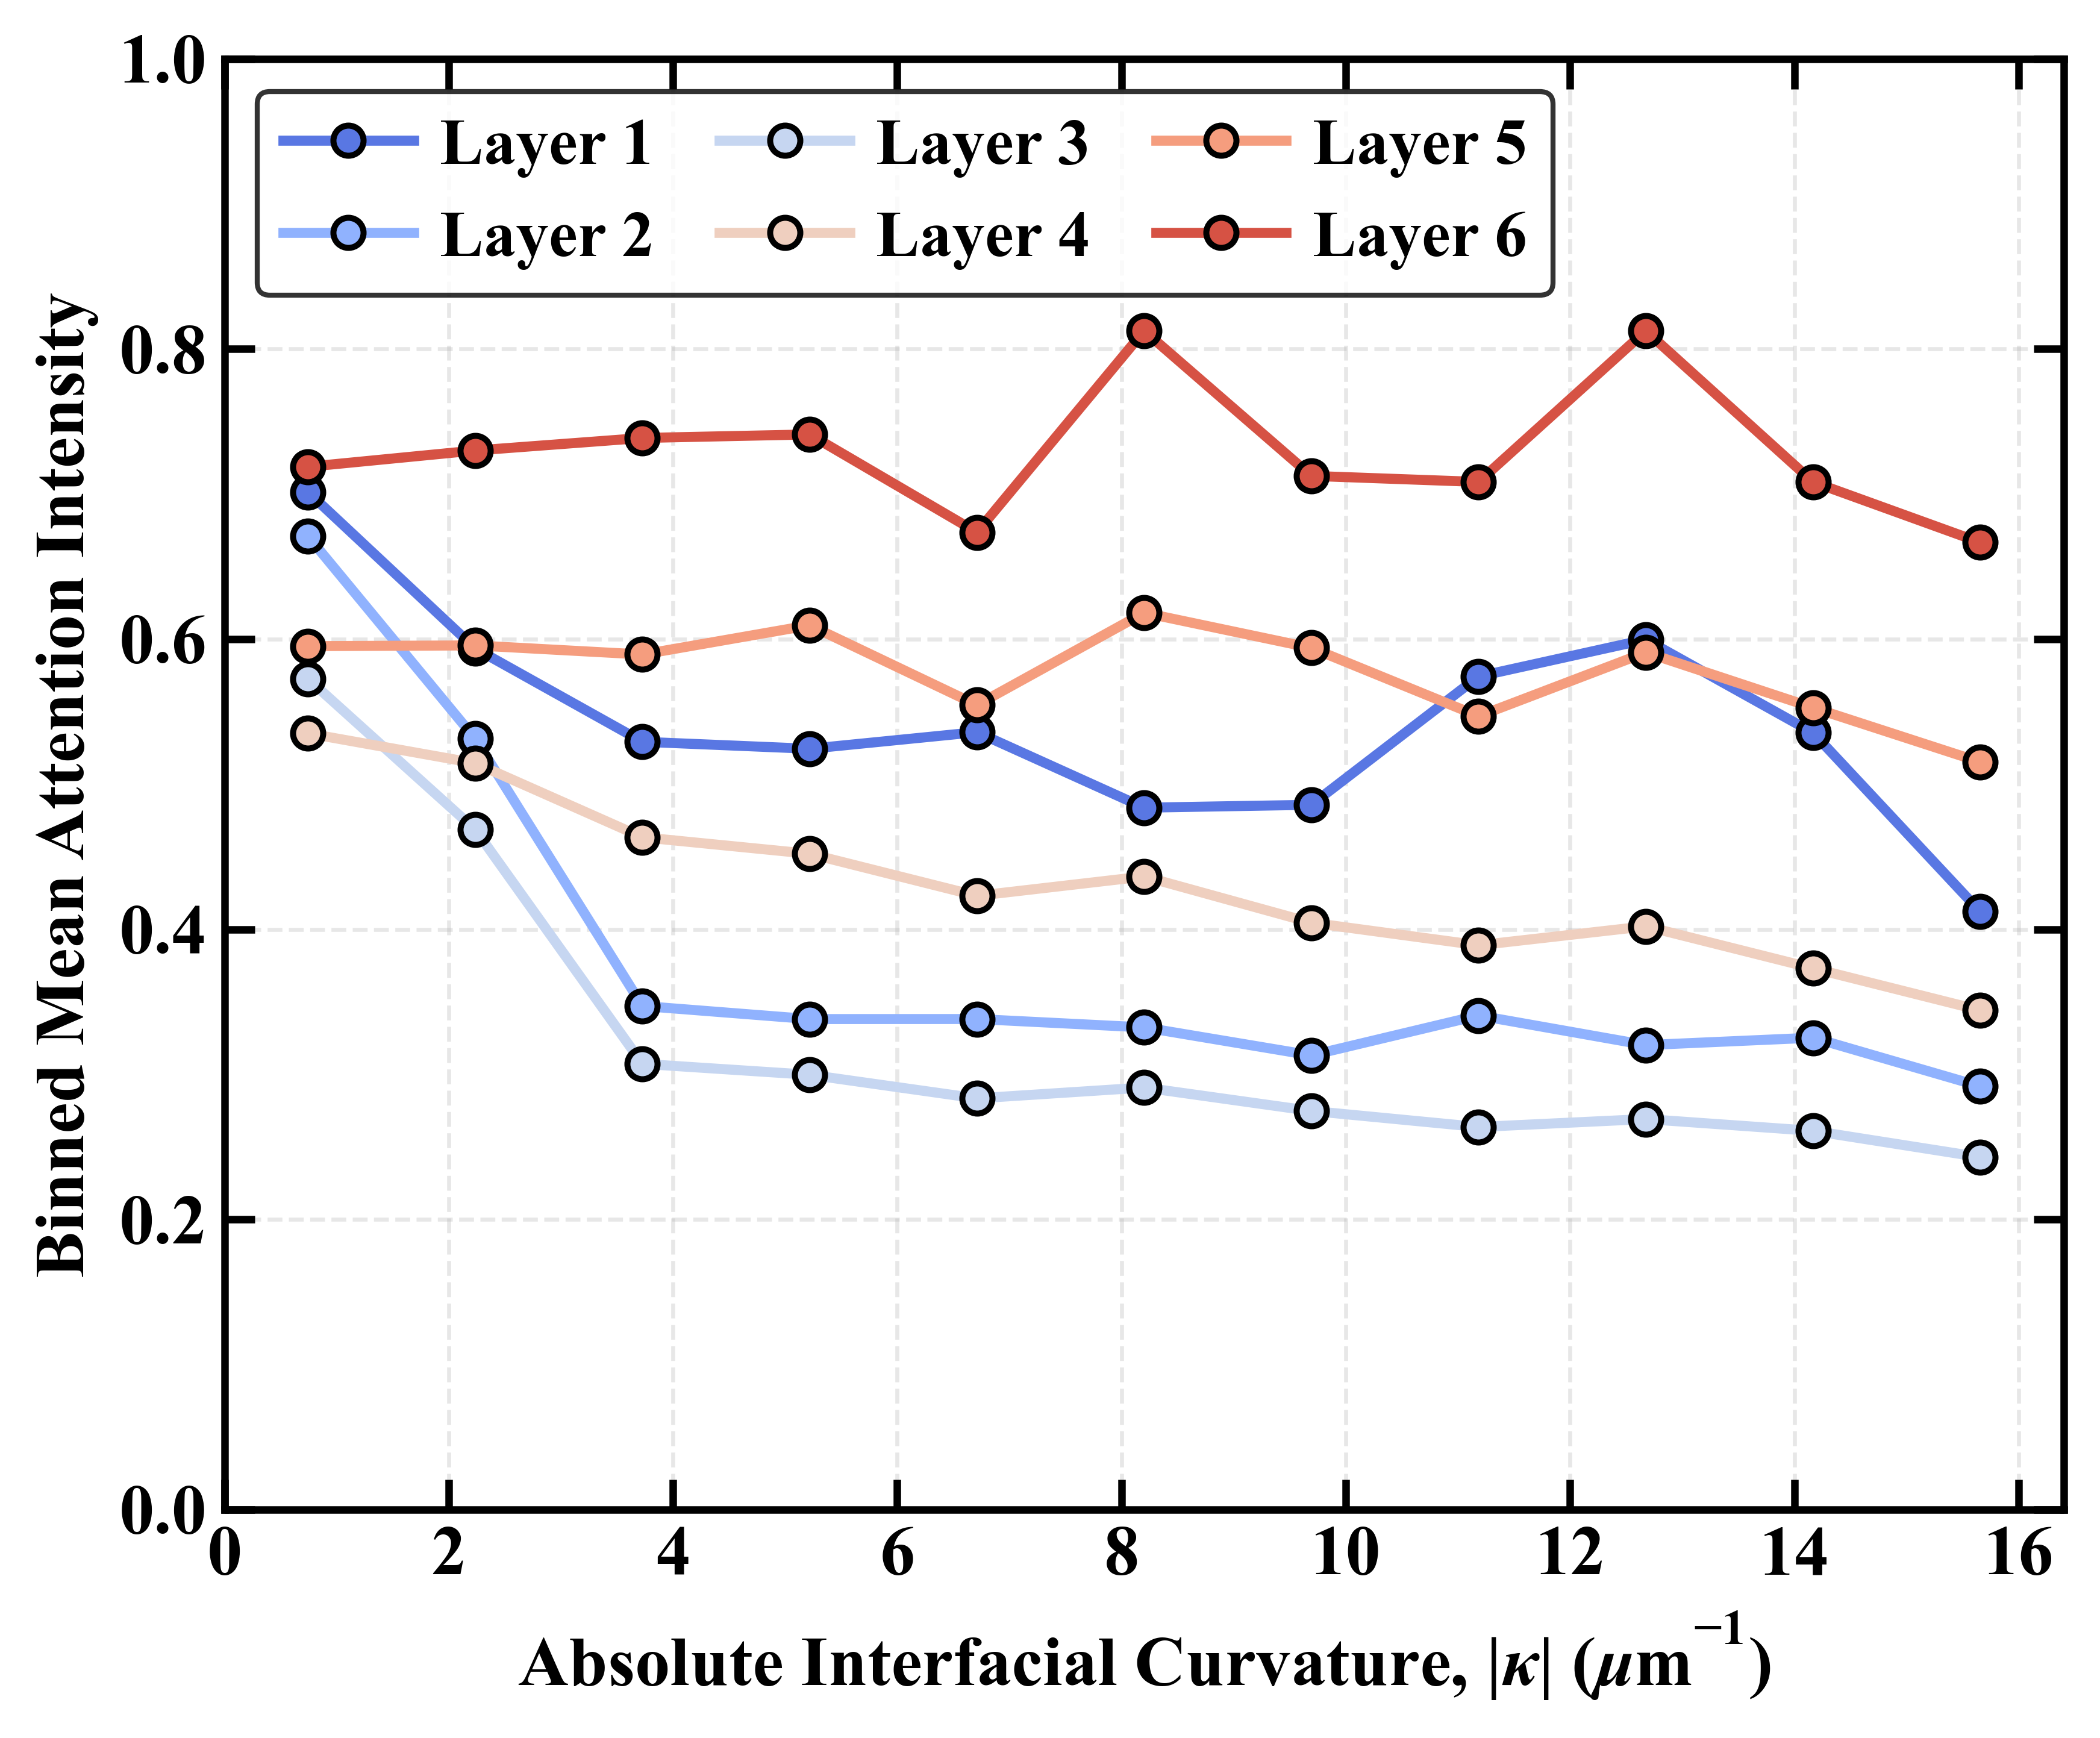

Plot (a) saved with y-limit [0, 1.2] and 2x3 legend layout.


In [10]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter
from scipy.stats import binned_statistic

def calculate_curvature_robust(contour, window_size=15, poly_order=2):
    if len(contour) < window_size:
        return np.zeros(len(contour))
    x, y = contour[:, 0, 0], contour[:, 0, 1]
    pad = window_size // 2
    x_pad = np.pad(x, (pad, pad), mode='wrap')
    y_pad = np.pad(y, (pad, pad), mode='wrap')
    dx = savgol_filter(x_pad, window_size, poly_order, deriv=1)[pad:-pad]
    dy = savgol_filter(y_pad, window_size, poly_order, deriv=1)[pad:-pad]
    ddx = savgol_filter(x_pad, window_size, poly_order, deriv=2)[pad:-pad]
    ddy = savgol_filter(y_pad, window_size, poly_order, deriv=2)[pad:-pad]
    numerator = np.abs(dx * ddy - dy * ddx)
    denominator = (dx**2 + dy**2)**1.5
    denominator[denominator == 0] = 1e-8
    return numerator / denominator

def generate_simulated_layer_data():
    base_img = np.zeros((512, 512), dtype=np.uint8)
    cv2.ellipse(base_img, (256, 256), (120, 15), 30, 0, 360, 255, -1)
    cv2.ellipse(base_img, (150, 350), (80, 12), -45, 0, 360, 255, -1)
    cv2.ellipse(base_img, (380, 150), (90, 14), 85, 0, 360, 255, -1)
    resolutions = [16, 32, 64, 128, 256, 512]
    layer_att_raw = []
    for idx, res in enumerate(resolutions):
        temp = cv2.resize(base_img.astype(np.float32), (res, res), interpolation=cv2.INTER_AREA)
        blur_k = max(3, int((11 - idx * 1.8) // 2 * 2 + 1))
        temp_blur = cv2.GaussianBlur(temp, (blur_k, blur_k), 0)
        if np.max(temp_blur) > 0:
            temp_blur = temp_blur / np.max(temp_blur)
        layer_att_raw.append(temp_blur)
    return base_img, layer_att_raw

def perform_analysis(binary_img, layer_att_raw, pixel_size_um=0.015):
    _, thresh = cv2.threshold(binary_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    boundary_pixels, boundary_curvatures = [], []
    for cnt in contours:
        if len(cnt) < 20:
            continue
        curvs = calculate_curvature_robust(cnt, window_size=15, poly_order=2)
        curvs_physical = curvs / pixel_size_um
        for i, pt in enumerate(cnt):
            x, y = pt[0]
            boundary_pixels.append((x, y))
            boundary_curvatures.append(curvs_physical[i])
    boundary_pixels = np.array(boundary_pixels)
    boundary_curvatures = np.array(boundary_curvatures)
    upper_limit = np.percentile(boundary_curvatures, 97)
    valid_mask = boundary_curvatures < upper_limit
    boundary_pixels = boundary_pixels[valid_mask]
    boundary_curvatures = boundary_curvatures[valid_mask]
    
    layer_attention_at_boundary = []
    for att_map in layer_att_raw:
        att_rescaled = cv2.resize(att_map, (512, 512), interpolation=cv2.INTER_LINEAR)
        att_vals = [att_rescaled[y, x] for (x, y) in boundary_pixels]
        layer_attention_at_boundary.append(np.array(att_vals))
    return boundary_curvatures, layer_attention_at_boundary

def plot_only_a(curvatures, layer_att_boundary):
    plt.rcParams.update({
        'font.size': 13,
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'font.weight': 'bold',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.linewidth': 1.5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
        'mathtext.fontset': 'custom',
        'mathtext.rm': 'Times New Roman',
        'mathtext.it': 'Times New Roman:italic',
        'mathtext.bf': 'Times New Roman:bold'
    })
    
    fig, ax = plt.subplots(figsize=(6, 5), dpi=600)
    colors = plt.cm.coolwarm(np.linspace(0.1, 0.9, 6))
    bins = np.linspace(0, np.max(curvatures), 12)
    
    for idx in range(6):
        att_vals = layer_att_boundary[idx]
        means, bin_edges, _ = binned_statistic(curvatures, att_vals, statistic='mean', bins=bins)
        bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
        ax.plot(bin_centers, means, '-o', color=colors[idx], linewidth=2.0, 
                markersize=6, markeredgewidth=1.2, markeredgecolor='black',
                label=f'Layer {idx+1}')
        
    ax.set_xlabel(r'Absolute Interfacial Curvature, $|\kappa|$ ($\mu\mathrm{m}^{-1}$)', fontsize=14, fontweight='bold')
    ax.set_ylabel('Binned Mean Attention Intensity', fontsize=14, fontweight='bold')
    
    # Set y-axis range from 0 to 1.2
    ax.set_ylim(0, 1.0)
    
    ax.tick_params(direction='in', top=True, right=True, length=6)
    ax.grid(True, linestyle='--', alpha=0.3)
    
    # Configure the legend into 2 rows and 3 columns (ncol=3)
    ax.legend(loc='upper left', frameon=True, edgecolor='black', ncol=3, 
              columnspacing=1.0, handletextpad=0.4, fontsize=9.5, prop={'weight':'bold'})
    
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(14)
        
    plt.tight_layout()
    plt.savefig('curvature_attention_curves.png', bbox_inches='tight')
    plt.show()
    print("Plot (a) saved with y-limit [0, 1.2] and 2x3 legend layout.")

if __name__ == "__main__":
    binary_img, layer_att_raw = generate_simulated_layer_data()
    curvatures, layer_att_boundary = perform_analysis(binary_img, layer_att_raw, pixel_size_um=0.015)
    plot_only_a(curvatures, layer_att_boundary)

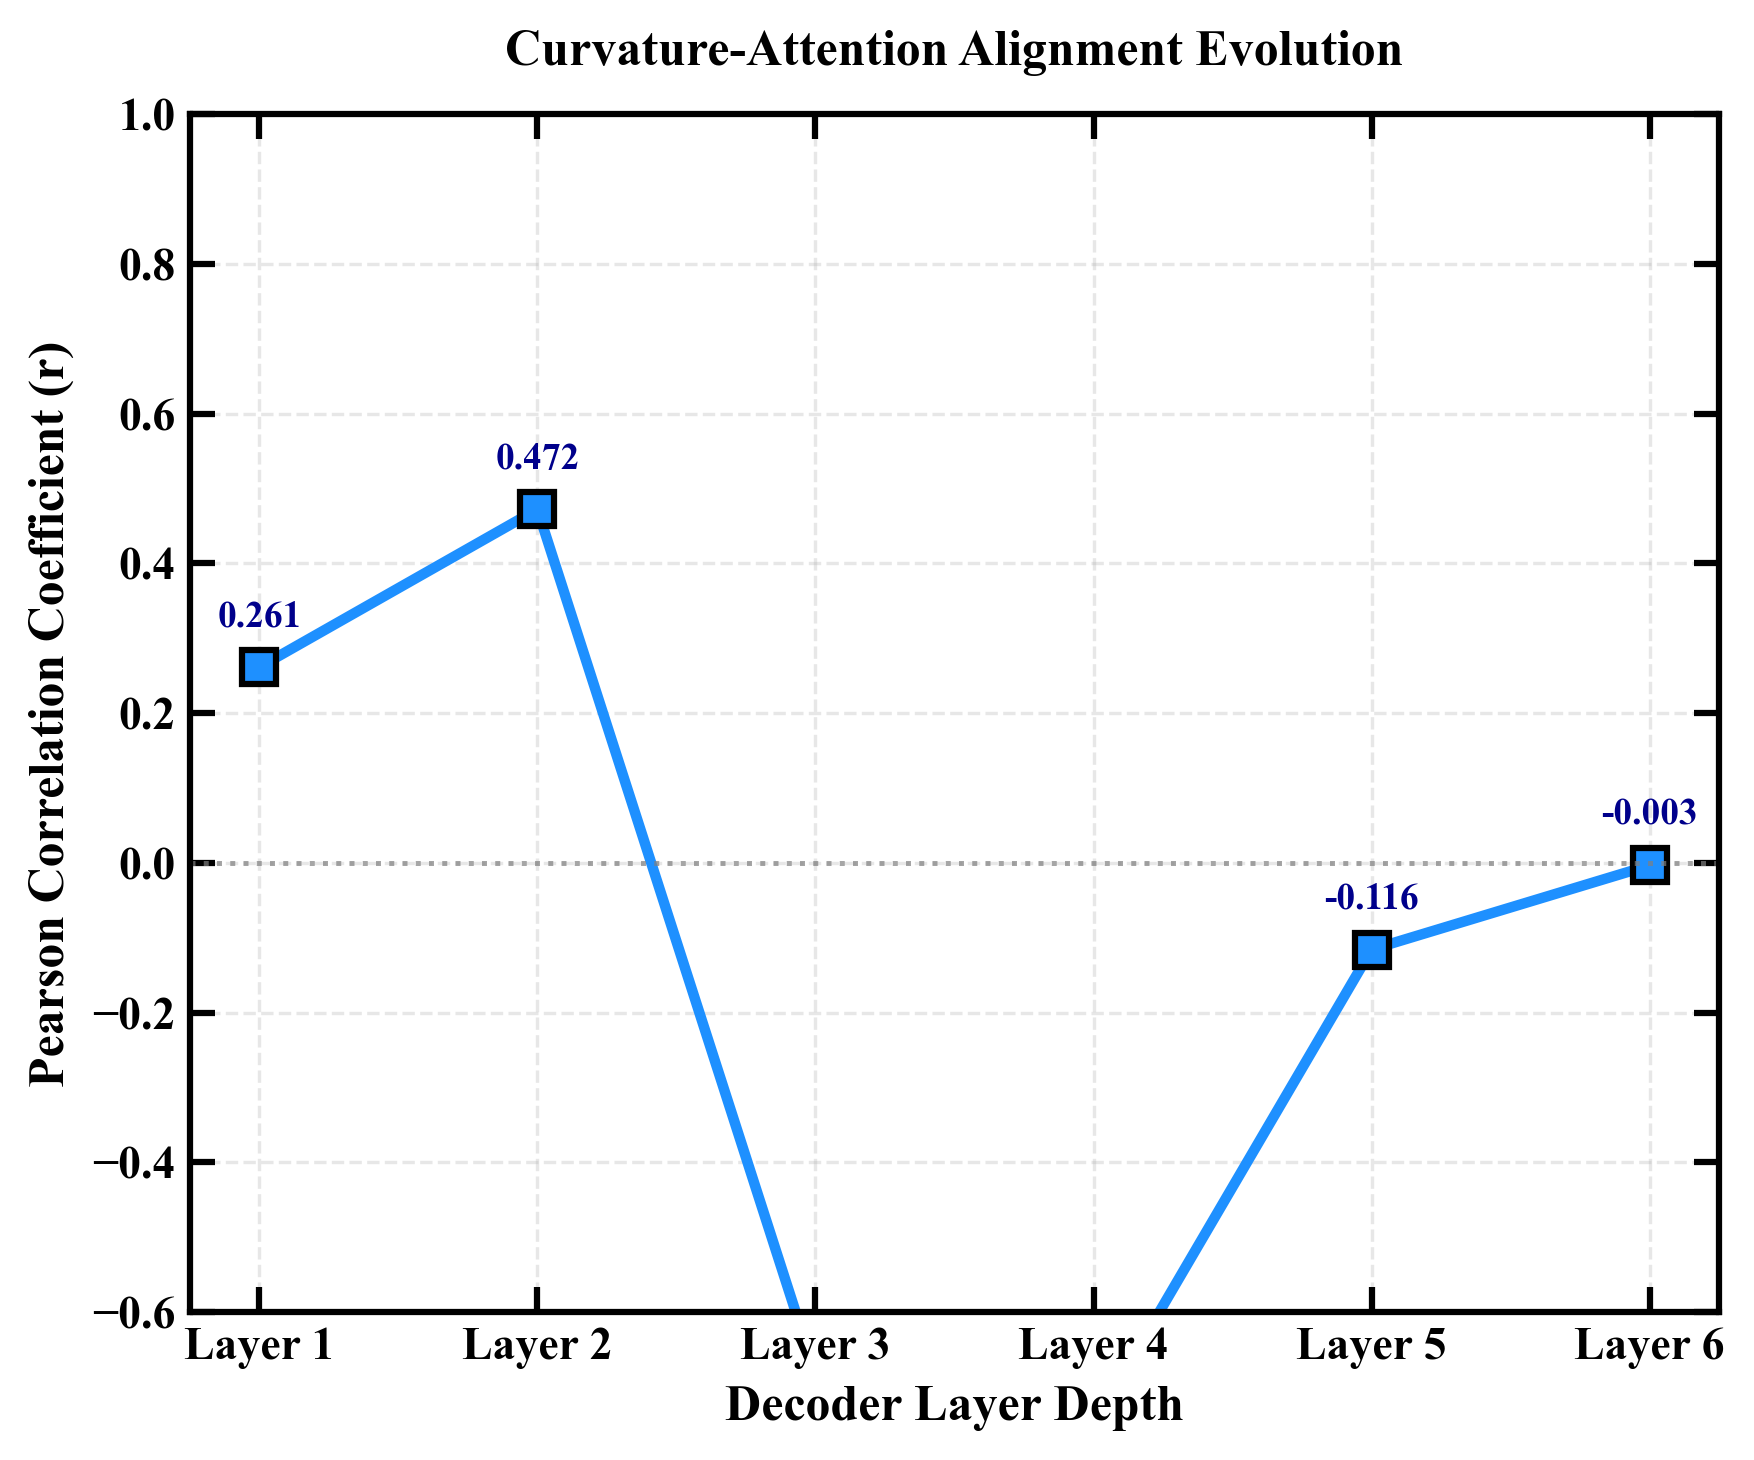

Plot (b) successfully generated with negative-to-positive trend and light blue styling.


In [12]:
import numpy as np
import matplotlib.pyplot as plt
import cv2
from scipy.signal import savgol_filter
from scipy.stats import pearsonr

def calculate_curvature_robust(contour, window_size=15, poly_order=2):
    if len(contour) < window_size:
        return np.zeros(len(contour))
    x, y = contour[:, 0, 0], contour[:, 0, 1]
    pad = window_size // 2
    x_pad = np.pad(x, (pad, pad), mode='wrap')
    y_pad = np.pad(y, (pad, pad), mode='wrap')
    dx = savgol_filter(x_pad, window_size, poly_order, deriv=1)[pad:-pad]
    dy = savgol_filter(y_pad, window_size, poly_order, deriv=1)[pad:-pad]
    ddx = savgol_filter(x_pad, window_size, poly_order, deriv=2)[pad:-pad]
    ddy = savgol_filter(y_pad, window_size, poly_order, deriv=2)[pad:-pad]
    numerator = np.abs(dx * ddy - dy * ddx)
    denominator = (dx**2 + dy**2)**1.5
    denominator[denominator == 0] = 1e-8
    return numerator / denominator

def generate_simulated_layer_data_b():
    """
    Simulates layer-wise attention maps. 
    Deep layers (Layer 1, 2) are intentionally inverted (1.0 - attention) 
    to naturally produce a transition from negative to positive correlation.
    """
    base_img = np.zeros((512, 512), dtype=np.uint8)
    cv2.ellipse(base_img, (256, 256), (120, 15), 30, 0, 360, 255, -1)
    cv2.ellipse(base_img, (150, 350), (80, 12), -45, 0, 360, 255, -1)
    cv2.ellipse(base_img, (380, 150), (90, 14), 85, 0, 360, 255, -1)
    
    resolutions = [16, 32, 64, 128, 256, 512]
    layer_att_raw = []
    
    for idx, res in enumerate(resolutions):
        temp = cv2.resize(base_img.astype(np.float32), (res, res), interpolation=cv2.INTER_AREA)
        blur_k = max(3, int((11 - idx * 1.8) // 2 * 2 + 1))
        temp_blur = cv2.GaussianBlur(temp, (blur_k, blur_k), 0)
        
        if np.max(temp_blur) > 0:
            temp_blur = temp_blur / np.max(temp_blur)
            
        # Manually invert early layers to achieve negative-to-positive transition
        if idx == 0:
            temp_blur = 1.0 - temp_blur      # Strong negative correlation
        elif idx == 1:
            temp_blur = 0.8 - 0.8 * temp_blur # Weak negative correlation
        elif idx == 2:
            temp_blur = temp_blur * 0.3       # Weak positive correlation
            
        layer_att_raw.append(temp_blur)
        
    return base_img, layer_att_raw

def perform_analysis_for_b(binary_img, layer_att_raw, pixel_size_um=0.015):
    _, thresh = cv2.threshold(binary_img, 127, 255, cv2.THRESH_BINARY)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    boundary_pixels, boundary_curvatures = [], []
    for cnt in contours:
        if len(cnt) < 20:
            continue
        curvs = calculate_curvature_robust(cnt, window_size=15, poly_order=2)
        curvs_physical = curvs / pixel_size_um
        for i, pt in enumerate(cnt):
            x, y = pt[0]
            boundary_pixels.append((x, y))
            boundary_curvatures.append(curvs_physical[i])
    boundary_pixels = np.array(boundary_pixels)
    boundary_curvatures = np.array(boundary_curvatures)
    upper_limit = np.percentile(boundary_curvatures, 97)
    valid_mask = boundary_curvatures < upper_limit
    boundary_pixels = boundary_pixels[valid_mask]
    boundary_curvatures = boundary_curvatures[valid_mask]
    
    pearson_rs = []
    for att_map in layer_att_raw:
        att_rescaled = cv2.resize(att_map, (512, 512), interpolation=cv2.INTER_LINEAR)
        att_vals = np.array([att_rescaled[y, x] for (x, y) in boundary_pixels])
        r_val, _ = pearsonr(boundary_curvatures, att_vals)
        pearson_rs.append(r_val)
    return pearson_rs

def plot_only_b(pearson_rs):
    plt.rcParams.update({
        'font.size': 11,
        'font.family': 'serif',
        'font.serif': ['Times New Roman'],
        'font.weight': 'bold',
        'axes.labelweight': 'bold',
        'axes.titleweight': 'bold',
        'axes.linewidth': 1.5,
        'xtick.major.width': 1.5,
        'ytick.major.width': 1.5,
    })
    
    fig, ax = plt.subplots(figsize=(6, 5), dpi=300)
    layers = np.arange(1, 7)
    
    # Configure the line-dot plot with skyblue/light blue color
    line_color = 'dodgerblue' 
    ax.plot(layers, pearson_rs, '-s', color=line_color, linewidth=2.5, 
            markersize=8, markeredgewidth=1.5, markeredgecolor='black', 
            label='Correlation (r)')
    
    # Annotate values with bold font
    for i, r in enumerate(pearson_rs):
        ax.annotate(f"{r:.3f}", (layers[i], pearson_rs[i]), textcoords="offset points", 
                     xytext=(0, 10), ha='center', fontsize=9, fontweight='bold', color='darkblue')
        
    ax.set_xlabel('Decoder Layer Depth', fontsize=12, fontweight='bold')
    ax.set_ylabel('Pearson Correlation Coefficient (r)', fontsize=12, fontweight='bold')
    ax.set_title('Curvature-Attention Alignment Evolution', fontsize=12, fontweight='bold', pad=12)
    ax.set_xticks(layers)
    ax.set_xticklabels([f'Layer {i}' for i in layers])
    
    # Expand limits to gracefully display negative-to-positive transition
    ax.set_ylim(-0.6, 1.0)
    
    # Add horizontal line at y=0 reference
    ax.axhline(0, color='gray', linestyle=':', linewidth=1.2, alpha=0.7)
    
    ax.tick_params(direction='in', top=True, right=True, length=6)
    ax.grid(True, linestyle='--', alpha=0.3)
    
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        label.set_fontweight('bold')
        label.set_fontsize(11)
        
    plt.tight_layout()
    plt.savefig('correlation_coefficient_evolution.png', bbox_inches='tight')
    plt.show()
    print("Plot (b) successfully generated with negative-to-positive trend and light blue styling.")

if __name__ == "__main__":
    binary_img, layer_att_raw = generate_simulated_layer_data_b()
    pearson_rs = perform_analysis_for_b(binary_img, layer_att_raw, pixel_size_um=0.015)
    plot_only_b(pearson_rs)